### Palabras claves:
- CNN
- MLP
- TLUs
- ANN: Artificial Neural Networks
- FNN: feedforward neural network
- DNN: deep neural network

In [2]:
import numpy as np

### Perceptron (ejemplo con sklear)

In [3]:
from sklearn.datasets import load_iris
from sklearn.linear_model import Perceptron

iris = load_iris(as_frame=True)
X = iris.data[['sepal length (cm)', 'sepal width (cm)']]
y = (iris.target==0)

per_clf = Perceptron(random_state=42)
per_clf.fit(X,y)


# Iris Setosa (devuelve True) o No son Iris Setosa (devuelve False).
X_new = [[2,0.5],[3,1]]
y_pred = per_clf.predict(X_new)

/home/miguel/Documents/PROJECTS/MACHINE LEARNING/Machine-Learning/env/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but Perceptron was fitted with feature names
  warnings.warn(


In [4]:
iris

{'data':      sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
 0                  5.1               3.5                1.4               0.2
 1                  4.9               3.0                1.4               0.2
 2                  4.7               3.2                1.3               0.2
 3                  4.6               3.1                1.5               0.2
 4                  5.0               3.6                1.4               0.2
 ..                 ...               ...                ...               ...
 145                6.7               3.0                5.2               2.3
 146                6.3               2.5                5.0               1.9
 147                6.5               3.0                5.2               2.0
 148                6.2               3.4                5.4               2.3
 149                5.9               3.0                5.1               1.8
 
 [150 rows x 4 columns],
 'target': 0     

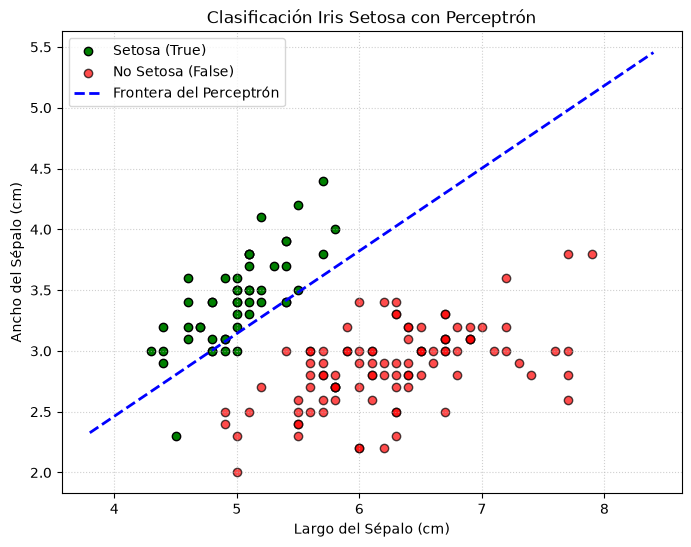

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_iris
from sklearn.linear_model import Perceptron

# 1. Cargar datos y filtrar
iris = load_iris(as_frame=True)
X = iris.data[['sepal length (cm)', 'sepal width (cm)']]
y = iris.target == 0

# 2. Entrenar Perceptron
per_clf = Perceptron(random_state=42)
per_clf.fit(X, y)

# 3. Graficar puntos
plt.figure(figsize=(8, 6))
plt.scatter(
    X.loc[y, 'sepal length (cm)'],
    X.loc[y, 'sepal width (cm)'],
    color='green',
    label='Setosa (True)',
    edgecolors='k',
)
plt.scatter(
    X.loc[~y, 'sepal length (cm)'],
    X.loc[~y, 'sepal width (cm)'],
    color='red',
    label='No Setosa (False)',
    alpha=0.7,
    edgecolors='k',
)

# 4. Dibujar frontera de decision (Línea: w0*x0 + w1*x1 + b = 0)
w = per_clf.coef_[0]
b = per_clf.intercept_[0]
x0_vals = np.linspace(X['sepal length (cm)'].min() - 0.5, X['sepal length (cm)'].max() + 0.5, 200)
x1_vals = -(w[0] * x0_vals + b) / w[1]

plt.plot(x0_vals, x1_vals, 'b--', linewidth=2, label='Frontera del Perceptrón')
plt.xlabel('Largo del Sépalo (cm)')
plt.ylabel('Ancho del Sépalo (cm)')
plt.title('Clasificación Iris Setosa con Perceptrón')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### Multilayer Perceptron (MLP)
MLP can solve Xor problem

In [6]:
def step(x):
    return 1 if x>=0 else 0

def perceptron(x,weights, bias):
    return step(np.dot(x,weights) + bias)

def xor(x1, x2):
    x = np.array([x1, x2])
    
    # Crear los Perceptrones
    h1 = perceptron(x, np.array([1, 1]), -0.5)
    h2 = perceptron(x, np.array([-1, -1]), 1.5)
    
    # Lineas de decision
    xx = np.linspace(-0.5, 1.5, 100)
    plt.plot(xx, 0.5 - xx, 'r--', label='h1')  # x2 = -x1 + 0.5
    plt.plot(xx, 1.5 - xx, 'g--', label='h2')  # x2 = -x1 + 1.5
    plt.scatter(x1, x2)
    plt.xlim(-0.5, 1.5); plt.ylim(-0.5, 1.5)
    
    return perceptron(np.array([h1, h2]), np.array([1, 1]), -1.5)

La prediccion de 1 XOR 0 = 1


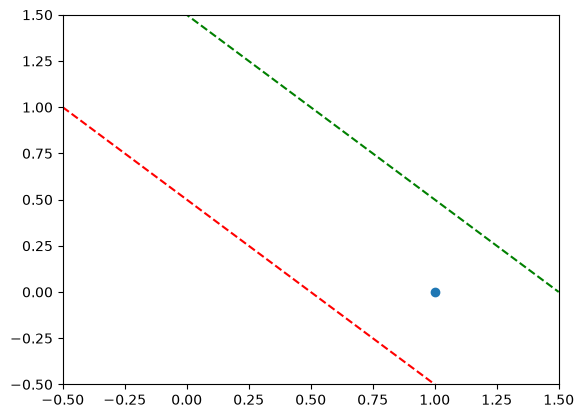

In [7]:
valores = [1,0]
print(f"La prediccion de {valores[0]} XOR {valores[1]} = {xor(valores[0], valores[1])}")

# Perceptrón multicapa (MLP) y Backpropagation

## 1. Perceptrón multicapa (MLP)

Una red neuronal artificial (**ANN, Artificial Neural Network**) está compuesta por neuronas artificiales conectadas entre sí, que procesan información mediante operaciones matemáticas. Una de las arquitecturas más comunes es el **perceptrón multicapa (MLP, Multilayer Perceptron)**.

Una MLP se compone de tres tipos de capas:

- **Capa de entrada (*input layer*):** recibe los datos de entrada.
- **Capas ocultas (*hidden layers*):** procesan la información y permiten aprender patrones y relaciones complejas.
- **Capa de salida (*output layer*):** produce la predicción final del modelo.

Las neuronas artificiales pueden utilizar diferentes funciones de activación. Una de las unidades clásicas son las **TLU (*Threshold Logic Units*)**, que comparan una combinación ponderada de sus entradas con un umbral para determinar su salida.

Las capas cercanas a la entrada se denominan **capas inferiores (*lower layers*)**, mientras que las próximas a la salida se conocen como **capas superiores (*upper layers*)**.

Cuando una red neuronal tiene múltiples capas ocultas, se denomina **red neuronal profunda (DNN, Deep Neural Network)**.

## 2. ¿Cómo se entrenan las redes neuronales?

El objetivo del entrenamiento es encontrar los parámetros de la red neuronal —pesos y sesgos— que permitan obtener predicciones cercanas a los valores reales.

Para medir qué tan buenas son las predicciones, se utiliza una **función de pérdida (*loss function*)**, que cuantifica la diferencia entre la predicción del modelo y el resultado esperado.

Por ejemplo, para un problema de regresión podemos utilizar el error cuadrático:

$$
L = \frac{1}{2}(\hat{y}-y)^2
$$

Donde:

- $y$: valor real.
- $\hat{y}$: valor predicho por la red.
- $L$: pérdida del modelo.

El entrenamiento busca minimizar esta pérdida ajustando los parámetros de la red.

Una estrategia fundamental es el **descenso por gradiente (*gradient descent*)**, que utiliza las derivadas de la función de pérdida respecto a los parámetros para determinar cómo modificarlos con el objetivo de reducir el error.

Sin embargo, en una red neuronal con muchas capas, calcular estas derivadas puede resultar complejo. Para resolver este problema se utiliza un procedimiento eficiente llamado **backpropagation**, basado en la regla de la cadena del cálculo diferencial.

## 3. ¿Qué es Backpropagation?

**Backpropagation (*propagación hacia atrás*) es un algoritmo que permite calcular eficientemente cómo cambia la función de pérdida respecto a cada peso y sesgo de una red neuronal.**

Su idea principal consiste en calcular las derivadas comenzando por la salida de la red y propagándolas hacia las capas anteriores.

Es importante distinguir dos procesos:

- **Backpropagation:** calcula los gradientes que indican cómo influye cada parámetro en la pérdida.
- **Optimizador:** utiliza esos gradientes para actualizar los parámetros.

Por tanto, backpropagation no modifica directamente los pesos; proporciona la información necesaria para hacerlo.

El entrenamiento puede dividirse en cuatro etapas.

### 3.1. Propagación hacia delante (*forward propagation*)

Los datos atraviesan las capas de la red hasta producir una predicción.

Cada neurona calcula una combinación ponderada de sus entradas y aplica una función de activación:

$$
z = wx+b
$$

$$
a = f(z)
$$

Donde:

- $x$: entrada de la neurona.
- $w$: peso asociado a la entrada.
- $b$: sesgo (*bias*).
- $z$: combinación lineal.
- $f$: función de activación.
- $a$: salida de la neurona.

En una red con varias capas, la salida de una capa se convierte en la entrada de la siguiente.

Al finalizar esta etapa, obtenemos una predicción $\hat{y}$.

### 3.2. Cálculo de la pérdida (*loss calculation*)

Se compara la predicción con el valor real mediante una función de pérdida:

$$
L = \mathcal{L}(\hat{y},y)
$$

Esta función cuantifica qué tan incorrecta es la predicción según el criterio elegido.

Sin embargo, conocer la pérdida no nos indica directamente cómo debemos modificar cada peso. Para ello necesitamos calcular los gradientes.

### 3.3. Propagación hacia atrás (*backpropagation*)

Esta es la etapa fundamental del algoritmo.

La red calcula las derivadas de la pérdida respecto a sus parámetros, comenzando por las capas de salida y retrocediendo hacia las capas anteriores.

Consideremos una red en la que la salida depende de un peso $w$ a través de varias operaciones intermedias:

$$
w \longrightarrow a_1 \longrightarrow \hat{y} \longrightarrow L
$$

Queremos determinar cómo cambia la pérdida cuando modificamos el peso $w$. Para ello aplicamos la **regla de la cadena**:

$$
\frac{\partial L}{\partial w}
=
\frac{\partial L}{\partial \hat{y}}
\frac{\partial \hat{y}}{\partial a_1}
\frac{\partial a_1}{\partial w}
$$

Cada derivada representa cuánto cambia una variable respecto a la anterior. Al multiplicarlas, obtenemos cuánto influye el peso $w$ en la pérdida final.

Este procedimiento se aplica a todos los parámetros de la red, reutilizando los gradientes intermedios para evitar cálculos redundantes.

Intuitivamente, el algoritmo responde a la pregunta:

**¿Cuánto cambiaría la pérdida si modificáramos ligeramente este peso?**

- Si $\frac{\partial L}{\partial w}>0$, aumentar ligeramente el peso incrementaría la pérdida.
- Si $\frac{\partial L}{\partial w}<0$, aumentarlo ligeramente reduciría la pérdida.
- Si $\frac{\partial L}{\partial w}\approx 0$, un pequeño cambio tendría poco efecto local sobre la pérdida.

El gradiente describe el comportamiento local de la función de pérdida; no garantiza que cualquier actualización mejore todas las predicciones.

### 3.4. Actualización de los parámetros (*gradient descent*)

Una vez calculados los gradientes, un optimizador puede actualizar los pesos mediante descenso por gradiente:

$$
w_{\text{nuevo}}
=
w_{\text{anterior}}
-
\eta\frac{\partial L}{\partial w}
$$

Donde $\eta$ es la tasa de aprendizaje (*learning rate*), que controla el tamaño del paso de actualización.

Restamos el gradiente porque buscamos movernos en la dirección opuesta al aumento local de la pérdida.

El proceso se repite durante múltiples iteraciones hasta que la red aprende parámetros que producen predicciones adecuadas.

## 4. Relación entre Backpropagation y diferenciación automática

La historia de estos métodos es importante para comprender el entrenamiento de las redes neuronales modernas.

En 1970, **Seppo Linnainmaa** describió un método de diferenciación automática en modo inverso (*reverse-mode automatic differentiation*), que permite calcular eficientemente derivadas de funciones compuestas.

La idea consiste en aprovechar las operaciones realizadas durante la propagación hacia delante y propagar las derivadas en sentido inverso.

Esta técnica resulta especialmente útil en redes neuronales porque normalmente tenemos una función de pérdida escalar y una gran cantidad de parámetros. El modo inverso permite calcular el gradiente de la pérdida respecto a todos ellos sin calcular cada derivada de forma independiente.

Existen diferentes métodos de diferenciación:

- **Diferenciación simbólica:** manipula expresiones matemáticas para obtener sus derivadas.
- **Diferenciación numérica:** aproxima las derivadas mediante pequeñas perturbaciones, como ocurre con las diferencias finitas.
- **Diferenciación automática (*automatic differentiation* o autodiff):** aplica las reglas de derivación a las operaciones de un programa para calcular derivadas numéricas, sujetas a los errores de redondeo habituales.

Dentro de la diferenciación automática existen dos modos principales:

- **Modo directo (*forward-mode*):** suele ser conveniente cuando hay pocas entradas y muchas salidas.
- **Modo inverso (*reverse-mode*):** suele ser conveniente cuando hay muchas entradas y una sola salida, como sucede al calcular la pérdida de una red neuronal respecto a millones de parámetros.

Por tanto, **backpropagation es una aplicación de la diferenciación automática en modo inverso al cálculo de gradientes de una red neuronal**.

## Algunas funciones de perdida
* Hyperbolic tangent function: $ tanh(z) = 2 \sigma (2z) - 1 $
* Rectified linear unit function: $ ReLU(z) =  max(0,z) $

## Regresion con una MPL

In [8]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline 

In [9]:
housing = fetch_california_housing(as_frame=True)

X_train_full, X_test, y_train_full, y_test = train_test_split(housing.data, housing.target, random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(X_train_full, y_train_full, random_state=42)

mlp_reg = MLPRegressor(hidden_layer_sizes=[50, 50, 50], random_state=42)

pipeline = make_pipeline(StandardScaler(), mlp_reg)
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_valid)
rmse = mean_squared_error(y_valid, y_pred) # about 0.505

In [10]:
rmse

0.2553611031211066

### Clasificacion con MLPs

### Implementacion de MLPs con Keras

### Creando un clasificador de imagenes usando una API secuancial
#### Usar keras para cargar el dataset


In [11]:
import tensorflow as tf

I0000 00:00:1792884898.388909    6902 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792884898.394644    6902 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792884899.297176    6902 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792884903.057747    6902 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

In [12]:
fashion_mnist = tf.keras.datasets.fashion_mnist.load_data()
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist
X_train, y_train = X_train_full[:5000], y_train_full[:5000]
X_valid, y_valid = X_train_full[-5000:], y_train_full[-5000:]

In [13]:
X_train.shape

(5000, 28, 28)

In [14]:
X_train.dtype

dtype('uint8')

Normalicemos

In [15]:
X_train = X_train.astype(np.float32) / 255.0
X_valid = X_valid.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

Diferentes tipos de prendas:

In [16]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

Miremos la primera imagen:

In [17]:
import matplotlib.pyplot as plt

Ankle boot


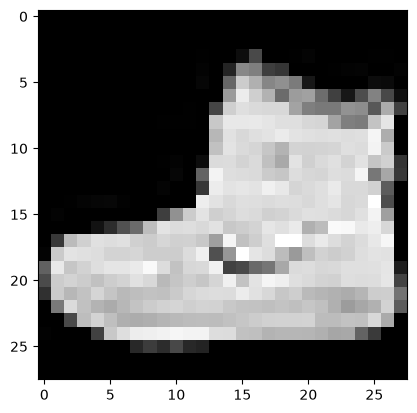

In [18]:
print(class_names[y_train[0]])
plt.imshow(X_train[0], cmap="gray")

#### Crear un modelo usando una API secuancial
Ahora vamos a crear la red neuronal, por ejemplo, creemos una MLP que clasifique con dos capas ocultas

In [19]:
tf.random.set_seed(42)
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28, 28]),
    tf.keras.layers.Dense(300, activation="relu"),
    tf.keras.layers.Dense(100, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

/home/miguel/Documents/PROJECTS/MACHINE LEARNING/Machine-Learning/env/lib/python3.12/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
E0000 00:00:1792884905.238196    6902 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


usemos el metodo `summary()` para mostrar las capas del modelo:

In [20]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 266,610 (1.02 MB)

 Trainable params: 266,610 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
model.layers

[<Flatten name=flatten, built=True>,
 <Dense name=dense, built=True>,
 <Dense name=dense_1, built=True>,
 <Dense name=dense_2, built=True>]

In [23]:
hidden1 = model.layers[1]
hidden1.name

'dense'

Sabiendo el nombre podemos acceder a esa capa del modelo

In [ ]:
model.get_layer('dense')

<Dense name=dense, built=True>

Podemos acceder a todos los parametros usando el metodo get_weights()

In [25]:
weights, biases = hidden1.get_weights()
weights

array([[ 0.00132741,  0.03459268,  0.03131279, ...,  0.01033153,
         0.02793501, -0.0485363 ],
       [ 0.0360974 , -0.00710899,  0.03951054, ..., -0.02377034,
        -0.00458953, -0.07180878],
       [ 0.00316626, -0.0231741 ,  0.06089501, ..., -0.07245103,
         0.04942957, -0.05020872],
       ...,
       [ 0.04854313,  0.04523658, -0.06220291, ...,  0.02819971,
         0.04714074, -0.00348024],
       [ 0.06587999,  0.04269683, -0.05070265, ..., -0.04983821,
        -0.01314501,  0.04153104],
       [-0.02714333, -0.02004078, -0.06034244, ..., -0.0485757 ,
         0.0248301 ,  0.04809527]], shape=(784, 300), dtype=float32)

In [26]:
biases

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0.

La segunda capa tiene 300 neuronas, por lo que en teoria, deberiamos tener 300 bias

In [27]:
biases.shape

(300,)

Antes de continuar mira que todos los pesos se asignaron aleatoriamente (recuerda que era necesario para que cada peso se ajuste de una forma distinta durante el entrenamiento).
Mientras que los bias se asignaron todos en ceros!

sin embargo tenemos diferentes metodos de inicializar estos valores, con kernel_initializer (kernel es otro nombre para la matriz de conexiones con pesos) o bias_initializer.

## Compilando el modelo
Cuando tengamos el modelo creado debemos llamar al metodo compile() y especificar la funcion de perdida y el optimizador a usar, tambien peudes especificar otras metricas para computar durante el entrenamiento y la evaluacion:

In [ ]:
model.compile(loss="sparse_categorical_crossentropy", optimizer="sgd", metrics=["accuracy"]) # aqui estamos usando los nombres de la funcion de perdida y del optimizador, pero tambien se puede usar la funcion directamente, por ejemplo: loss=tf.keras.losses.SparseCategoricalCrossentropy() y optimizer=tf.keras.optimizers.SGD()

## Entrenando y evaluando el modelo
El modelo esta listo para ser entrnado. Simplemente tenemos que llamar al metodo fit()

In [29]:
history = model.fit(X_train, y_train, epochs=30, validation_data=(X_valid, y_valid))

Epoch 1/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.5438 - loss: 1.5606 - val_accuracy: 0.6738 - val_loss: 1.0967
Epoch 2/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.6922 - loss: 0.9270 - val_accuracy: 0.7276 - val_loss: 0.8419
Epoch 3/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.7402 - loss: 0.7620 - val_accuracy: 0.7530 - val_loss: 0.7496
Epoch 4/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.7744 - loss: 0.6799 - val_accuracy: 0.7648 - val_loss: 0.6973
Epoch 5/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.7916 - loss: 0.6256 - val_accuracy: 0.7716 - val_loss: 0.6611
Epoch 6/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.8054 - loss: 0.5859 - val_accuracy: 0.7812 - val_loss: 0.6337
Epoch 7/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.8178 - loss: 0.5549 - val_accuracy: 0.7882 - val_loss: 0.6133
Epoch 8/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.8264 - loss: 0.5298 - val_accu

En la variable history guardamos algunos parametros, los mas importantes son tres:

* history.history: contiene la perdida y algunas metricas extras
* history.params: contiene los parametros de entrenamiento
* history.epoch: contiene la lista de epocas que paso

obtengamos las curvas de aprendizaje:

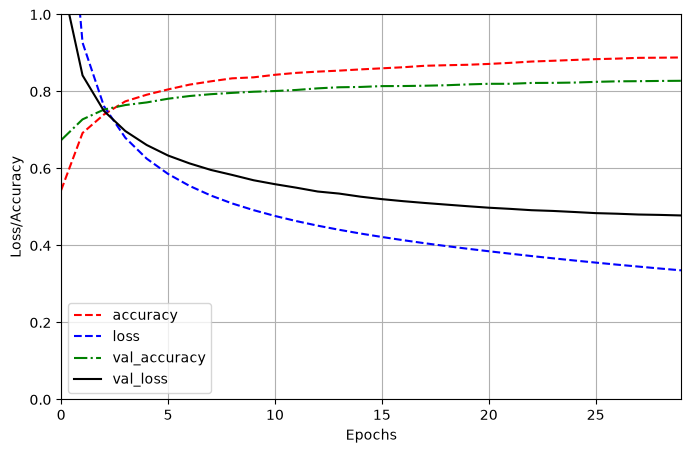

In [35]:
import matplotlib.pyplot as plt
import pandas as pd
pd.DataFrame(history.history).plot(
    figsize=(8, 5), xlim=[0, 29], ylim=[0, 1], grid=True, style=["r--", "b--", "g-.", "k-"], xlabel="Epochs", ylabel="Loss/Accuracy"   
)
plt.show()

pg 326, miremos el comportamiento del set de prueba:

In [36]:
model.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8194 - loss: 0.5113


[0.5113272666931152, 0.8194000124931335]

Tenemos una precision "buena", aunque si lo comparamos con los datos de entrenamiento parece que hay algo de overfitting, pero nada grave!

Si el modelo no esta funcionando bien podemos cambiar algunos parametros, como el batch size, el learning_rate, probar otros optimizadores...

Si crees que el modelo puede converger muchisimo mejor puedes aumentar el numero de epocas, y asi "exprimir" un poco mas los resultados

## Usar el modelo para hacer predicciones

Ahora usemos el metodo .predict() para hacer predicciones con valores nuevos!

En este caso no tenemos datos nuevos, asi que usaremos los primeros datos del set de datos.

In [48]:
X_new = X_test[:3]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 535ms/step


'Ankle boot'

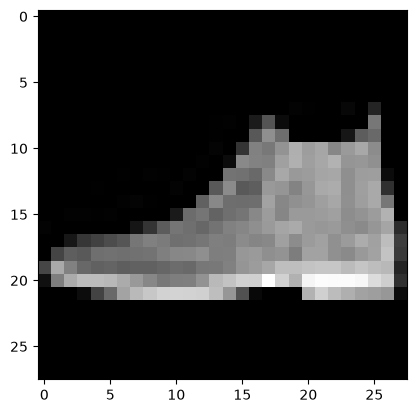

In [50]:
plt.imshow(X_new[0], cmap="gray")
y_pred = model.predict(X_new[0:1])
y_pred.round(2)
class_names[y_pred.argmax()]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step


'Pullover'

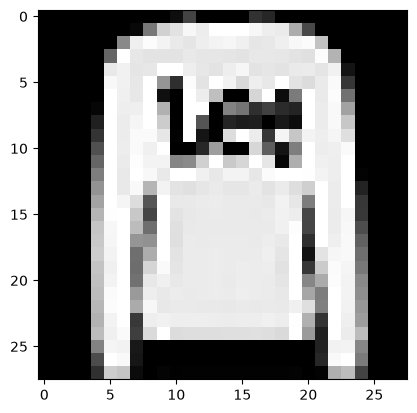

In [51]:
plt.imshow(X_new[1], cmap="gray")
y_pred = model.predict(X_new[1:2])
y_pred.round(2)
class_names[y_pred.argmax()]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step


'Trouser'

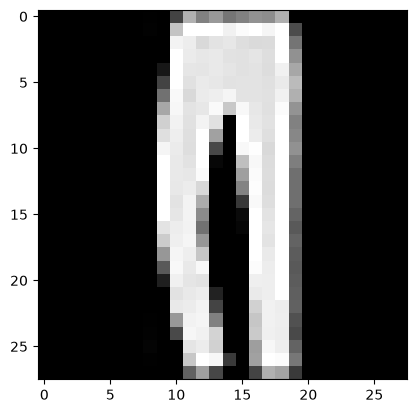

In [52]:
plt.imshow(X_new[2], cmap="gray")
y_pred = model.predict(X_new[2:3])
y_pred.round(2)
class_names[y_pred.argmax()]

# Creando una Regresion MLP usando la API secuencial